# 03 — Modell A: Kaltmiete pro m²

**Ziel:** Vorhersage der Kaltmiete in €/m² (`mietekalt_qm`) mittels verschiedener Regressionsmodelle  
**Modelle:** Lineare Regression · Decision Tree · XGBoost · LightGBM · TabPFN · EBM · IGANN  
**Datenquelle:** `WM_SUF_ohneText.csv` → bereinigt als `wm_clean.parquet`  
**Zielgröße:** `mietekalt_qm = mietekalt / wohnflaeche` (€/m²)

---
**Struktur:**
1. Imports & Konfiguration  
2. Daten laden & Sampling  
3. Zielgröße & Features  
4. Train/Test-Split  
5. Baseline-Modelle  
6. Advanced Flexible (XGBoost, LightGBM)  
7. TabPFN  
8. EBM  
9. IGANN  
10. Hyperparameter-Tuning (Optuna)  
11. Evaluierung & Vergleichstabelle  
12. Modelle speichern

In [1]:
import sys
import os
import warnings
from pathlib import Path
sys.path.append('..')
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import joblib
import json

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
import xgboost as xgb
import lightgbm as lgb
from interpret.glassbox import ExplainableBoostingRegressor
from igann import IGANN

from src.data.preprocessing import (
    FEATURE_COLS, FEATURES_WITH_NAN,
    NUMERICAL_FEATURES, CATEGORICAL_FEATURES, CAT_STRING_COLS,
    TARGET_PRICE,
    load_parquet, prepare_features, prepare_target_price, stratified_sample,
    prepare_features_for_trees, prepare_features_for_linear,
)

# ============================================================
# KONFIGURATION
# ============================================================
RUN_FINAL = True  # True = 10%-Sample (finale Modelle), False = 1%-Sample (Entwicklung)

SAMPLE_FRAC_DEV   = 0.01
SAMPLE_FRAC_FINAL = 0.10
RANDOM_STATE      = 42
TABICL_MAX_ROWS   = 5_000   # CPU-Limit fuer TabICLv2; Kollege nutzt GPU
NOTEBOOK          = 'A'

DATA_PATH  = '../data/processed/AUTO_final_enriched.parquet'
MODELS_DIR = Path("../models")
TARGET_COL = TARGET_PRICE
# ============================================================

print(f"Modus: {'FINAL (10% Sample)' if RUN_FINAL else 'DEV (1% Sample)'}")
print(f"Zielgroesse: {TARGET_COL}")


Modus: FINAL (10% Sample)
Zielgroesse: mietepro_m2


In [2]:
frac = SAMPLE_FRAC_FINAL if RUN_FINAL else SAMPLE_FRAC_DEV

df_full = load_parquet(DATA_PATH)
print(f"Geladene Zeilen: {len(df_full):,} | Spalten: {df_full.shape[1]}")

df_sample = stratified_sample(df_full, frac=frac, seed=RANDOM_STATE)
print(f"Stichprobe ({frac*100:.1f}%): {len(df_sample):,} Zeilen")
print(f"\nJahres-Verteilung:\n{df_sample['ajahr'].value_counts().sort_index().to_string()}")

# Reproduzierbarer Sample-Index sichern (nur bei finalem Run)
# Kollege: gleiche AUTO_final_enriched.parquet + stratified_sample(frac=0.10, seed=42) = identischer Sample
if RUN_FINAL:
    _orig_idx = pd.concat([
        grp.sample(frac=frac, random_state=RANDOM_STATE)
        for _, grp in df_full.groupby("ajahr")
    ]).index.to_series().reset_index(drop=True)
    _orig_idx.to_csv("../data/processed/sample_10pct_index.csv", index=False, header=["original_index"])
    print(f"\nSample-Index gespeichert: ../data/processed/sample_10pct_index.csv")
    print("Reproduzierbarkeit: gleiche Parquet-Datei + seed=42 liefert identischen Sample.")


Geladene Zeilen: 11,505,472 | Spalten: 42
Stichprobe (10.0%): 1,150,546 Zeilen

Jahres-Verteilung:
ajahr
2007    53765
2008    53627
2009    58942
2010    63948
2011    61409
2012    59158
2013    65382
2014    87383
2015    74263
2016    55626
2017    55056
2018    54422
2019    53519
2020    61374
2021    62900
2022    48110
2023    51414
2024    60331
2025    69917

Sample-Index gespeichert: ../data/processed/sample_10pct_index.csv
Reproduzierbarkeit: gleiche Parquet-Datei + seed=42 liefert identischen Sample.


In [3]:
X = prepare_features(df_sample)
y = prepare_target_price(df_sample)

print(f"Feature-Matrix: {X.shape}")
print(f"NaN-Anteil: {X.isna().mean().mean()*100:.1f}%")
print(f"\nZielgr\u00f6\u00dfe '{TARGET_COL}' Statistiken:\n{y.describe().round(4).to_string()}")


Feature-Matrix: (1150546, 32)
NaN-Anteil: 6.5%

Zielgröße 'mietepro_m2' Statistiken:
count    1.150546e+06
mean     8.720500e+00
std      4.224900e+00
min      3.722200e+00
25%      5.777800e+00
50%      7.520500e+00
75%      1.031750e+01
max      2.650000e+01


In [4]:
# ============================================================
# TEMPORALER TRAIN/TEST-SPLIT
# Train: ajahr ≤ 2022 | Test: ajahr 2023–2025
# Strukturbruch 2022 (Zinsschock/Post-COVID) im Training enthalten.
# Echter Out-of-Sample-Zeitschnitt — kein temporales Data-Leakage.
# ============================================================
TEMPORAL_CUTOFF = 2022

mask_train = df_sample["ajahr"] <= TEMPORAL_CUTOFF
mask_test  = df_sample["ajahr"] >  TEMPORAL_CUTOFF

X_train = X[mask_train]
X_test  = X[mask_test]
y_train = y[mask_train]
y_test  = y[mask_test]

print(f"Trainingsset: {X_train.shape[0]:,} Zeilen ({mask_train.mean()*100:.1f}%) | ajahr ≤ {TEMPORAL_CUTOFF}")
print(f"Testset:      {X_test.shape[0]:,} Zeilen ({mask_test.mean()*100:.1f}%) | ajahr > {TEMPORAL_CUTOFF}")
print(f"Features:     {X_train.shape[1]}")
print(f"\nTrain-Jahresverteilung:\n{df_sample.loc[mask_train, 'ajahr'].value_counts().sort_index().to_string()}")
print(f"\nTest-Jahresverteilung:\n{df_sample.loc[mask_test, 'ajahr'].value_counts().sort_index().to_string()}")


Trainingsset: 968,884 Zeilen (84.2%) | ajahr ≤ 2022
Testset:      181,662 Zeilen (15.8%) | ajahr > 2022
Features:     32

Train-Jahresverteilung:
ajahr
2007    53765
2008    53627
2009    58942
2010    63948
2011    61409
2012    59158
2013    65382
2014    87383
2015    74263
2016    55626
2017    55056
2018    54422
2019    53519
2020    61374
2021    62900
2022    48110

Test-Jahresverteilung:
ajahr
2023    51414
2024    60331
2025    69917


In [5]:
# ============================================================
# ENCODING & IMPUTATION -- nach Train/Test-Split (kein Leakage moeglich)
# Gruppe 1 (XGBoost, LightGBM, Decision Tree):
#   -> imputiert + OrdinalEncoder fuer String-Kategorien -> X_train_tree
#   Hinweis: V1.5 speichert Kategorien als str (defensives Encoding) -- Baummodelle
#   benoetigen numerischen Input.
# Gruppe 2a (EBM):
#   -> imputiert, String-Kategorien bleiben als str -> X_train_imp
#   EBM (interpret) verarbeitet String-Features nativ, benoetigt aber object dtype.
# Gruppe 2b (LR, IGANN, TabICLv2):
#   -> imputiert + OHE (ohne erg_amd, 141 Kategorien) -> X_train_lr
#   -> IGANN zusaetzlich mit StandardScaler wie in NB06-HPA
# ============================================================
NUM_NAN_COLS = [c for c in NUMERICAL_FEATURES if c in FEATURES_WITH_NAN]
CAT_NAN_COLS = [c for c in CATEGORICAL_FEATURES if c in FEATURES_WITH_NAN]

num_imputer = SimpleImputer(strategy="median")
cat_imputer = SimpleImputer(strategy="most_frequent")

# Basis-Imputation fuer alle Gruppen (fit NUR auf X_train -> kein Leakage)
X_train_imp = X_train.copy()
X_test_imp  = X_test.copy()

X_train_imp[NUM_NAN_COLS] = num_imputer.fit_transform(X_train[NUM_NAN_COLS])
X_test_imp[NUM_NAN_COLS]  = num_imputer.transform(X_test[NUM_NAN_COLS])

X_train_imp[CAT_NAN_COLS] = cat_imputer.fit_transform(X_train[CAT_NAN_COLS])
X_test_imp[CAT_NAN_COLS]  = cat_imputer.transform(X_test[CAT_NAN_COLS])

# pandas 2.x speichert str-Spalten als StringDtype -- EBM (interpret) unterstuetzt
# nur object dtype. Alle StringDtype-Spalten zu object konvertieren.
_str_cols = X_train_imp.select_dtypes(include="string").columns.tolist()
if _str_cols:
    X_train_imp[_str_cols] = X_train_imp[_str_cols].astype(object)
    X_test_imp[_str_cols]  = X_test_imp[_str_cols].astype(object)
    print(f"StringDtype -> object: {_str_cols}")

print("Imputation abgeschlossen")
print(f"   X_train_imp: {X_train_imp.shape[1]} Features, NaN: {X_train_imp.isna().sum().sum()}")

# Gruppe 1: OrdinalEncoder fuer String-Kategorien (V1.5 -- defensives str-Encoding)
# XGBoost, LightGBM, Decision Tree koennen keine str-Spalten verarbeiten
X_train_tree, X_test_tree, ord_encoder = prepare_features_for_trees(X_train_imp, X_test_imp)
print(f"OrdinalEncoder (Gruppe 1): {len(CAT_STRING_COLS)} String-Spalten -> int kodiert")
print(f"   X_train_tree: {X_train_tree.shape[1]} Features")

# Gruppe 2b: OHE fuer LR + IGANN + TabICLv2 (erg_amd gedroppt -- 141 Kategorien)
X_train_lr, X_test_lr, ohe_encoder = prepare_features_for_linear(X_train_imp, X_test_imp)
print(f"OHE (Gruppe 2b): {X_train_lr.shape[1]} Features fuer LR/IGANN/TabICLv2 (ohne erg_amd)")

igann_scaler = StandardScaler()
X_train_igann = pd.DataFrame(
    igann_scaler.fit_transform(X_train_lr),
    index=X_train_lr.index,
    columns=X_train_lr.columns,
).replace([np.inf, -np.inf], np.nan).fillna(0.0)
X_test_igann = pd.DataFrame(
    igann_scaler.transform(X_test_lr),
    index=X_test_lr.index,
    columns=X_test_lr.columns,
).replace([np.inf, -np.inf], np.nan).fillna(0.0)
print(f"IGANN-Scaling: {X_train_igann.shape[1]} Features standardisiert")


StringDtype -> object: ['objektzustand', 'heizungsart', 'kategorie_Wohnung', 'blid', 'erg_amd']
Imputation abgeschlossen
   X_train_imp: 32 Features, NaN: 0
OrdinalEncoder (Gruppe 1): 5 String-Spalten -> int kodiert
   X_train_tree: 32 Features
OHE (Gruppe 2b): 71 Features fuer LR/IGANN/TabICLv2 (ohne erg_amd)
IGANN-Scaling: 71 Features standardisiert


In [6]:
results = []

def evaluate_model(name, y_true, y_pred):
    """Berechnet MAE, RMSE, R² -- direkt auf Preis-Skala (Euro/m2)."""
    return {
        "Modell": name,
        "MAE":    round(mean_absolute_error(y_true, y_pred), 4),
        "RMSE":   round(np.sqrt(mean_squared_error(y_true, y_pred)), 4),
        "R²":     round(r2_score(y_true, y_pred), 4),
    }

print("evaluate_model definiert.")


evaluate_model definiert.


In [7]:
# # TabICLv2 -- In-Context Learning Foundation Model
# # Erzwingt CPU, damit gespeicherte Joblib auf CPU-Umgebungen ladbar bleibt.
# # CPU-Limit: ~512 Zeilen (Attention-NaN bei groesseren Sequenzen).
# print(f"Training: TabICLv2 (Sub-Sample <={TABICL_MAX_ROWS:,})...")

# try:
#     from tabicl import TabICLRegressor

#     idx = np.random.default_rng(RANDOM_STATE).choice(
#         len(X_train_lr), size=min(TABICL_MAX_ROWS, len(X_train_lr)), replace=False
#     )
#     X_train_tabicl = X_train_lr.iloc[idx]
#     y_train_tabicl = y_train.iloc[idx]

#     tabicl_model = TabICLRegressor(device="cpu")
#     tabicl_model.fit(X_train_tabicl, y_train_tabicl)
#     y_pred_tabicl = tabicl_model.predict(X_test_lr)
#     results.append(evaluate_model("TabICLv2", y_test, y_pred_tabicl))
#     print(f"  -> MAE: {results[-1]['MAE']:.4f} Euro/m2 | R2: {results[-1]['R²']:.4f}")

# except ImportError:
#     print("  TabICLv2 nicht installiert -- uebersprungen.")
#     tabicl_model = None
# except Exception as e:
#     print(f"  TabICLv2 Fehler: {e}")
#     tabicl_model = None

In [8]:
# ============================================================
# HPA-Parameter aus NB06 laden (kanonische Quelle fuer alle Hyperparameter)
# NB06 (06_hyperparameter_analysis.ipynb) ist das einzige HPA-Notebook.
# Diese Zelle ersetzt die frueheren eigenen Optuna-Studies (Testcode) und
# verhindert Race Conditions beim Ueberschreiben von models/best_params_*.json.
# ============================================================
def _load_best_params(filename: str) -> dict:
    path = MODELS_DIR / filename
    if not path.exists():
        print(f"  WARNUNG: {filename} nicht gefunden. Zuerst NB06 ausfuehren!")
        return {}
    with open(path) as f:
        params = json.load(f)
    print(f"  Geladen: {filename} -> {params}")
    return params

print("Lade HPA-Parameter aus NB06 (models/best_params_*.json) ...")
best_params_xgb   = _load_best_params("best_params_xgb_price.json")
best_params_lgbm  = _load_best_params("best_params_lgbm_price.json")
best_params_ebm   = _load_best_params("best_params_ebm_price.json")
best_params_igann = _load_best_params("best_params_igann_price.json")
best_params_lr    = _load_best_params("best_params_lr_price.json")
print("\nAlle HPA-Parameter geladen. Naechste Zelle: finales Modell-Training.")


Lade HPA-Parameter aus NB06 (models/best_params_*.json) ...
  Geladen: best_params_xgb_price.json -> {'n_estimators': 1427, 'learning_rate': 0.03623906068902309, 'max_depth': 8, 'subsample': 0.938775128172194, 'colsample_bytree': 0.5143558233340128, 'reg_alpha': 1.866334065330432e-06, 'reg_lambda': 2.5540334557542108e-06, 'min_child_weight': 3}
  Geladen: best_params_lgbm_price.json -> {'n_estimators': 1499, 'learning_rate': 0.02643122167187603, 'max_depth': 12, 'num_leaves': 244, 'subsample': 0.8311333525427284, 'colsample_bytree': 0.5361525317903245, 'reg_alpha': 0.08313656426695509, 'reg_lambda': 0.5797566399152478}
  Geladen: best_params_ebm_price.json -> {'max_bins': 359, 'max_interaction_bins': 38, 'interactions': 20, 'learning_rate': 0.08805617479545157, 'min_samples_leaf': 16, 'max_rounds': 4996}
  Geladen: best_params_igann_price.json -> {'n_hid': 64, 'n_estimators': 500, 'boost_rate': 0.19030368381735815, 'elm_scale': 0.7725378389307354, 'elm_alpha': 0.13311216080736885}
  Ge

In [9]:
# # ============================================================
# # FINALE MODELLE MIT HPA-PARAMETERN (aus NB06)
# # Deine Modelle: LightGBM, EBM, IGANN, Ridge
# # ============================================================

# # --- LightGBM tuned (Gruppe 1: OrdinalEncoded) ---
# print("Training: LightGBM (tuned)...")
# lgbm_tuned = lgb.LGBMRegressor(
#     random_state=RANDOM_STATE, n_jobs=-1, verbose=-1,
#     **best_params_lgbm
# )
# lgbm_tuned.fit(X_train_tree, y_train)
# y_pred_lgbm_tuned = lgbm_tuned.predict(X_test_tree)
# results.append(evaluate_model("LightGBM (tuned)", y_test, y_pred_lgbm_tuned))
# print(f"  -> MAE: {results[-1]['MAE']:.4f} Euro/m2 | R2: {results[-1]['R²']:.4f}")

# # --- EBM tuned (Gruppe 2a: imputiert, String-Features nativ) ---
# print("Training: EBM (tuned)...")
# ebm_tuned = ExplainableBoostingRegressor(
#     random_state=RANDOM_STATE,
#     **best_params_ebm
# )
# ebm_tuned.fit(X_train_imp, y_train)
# y_pred_ebm_tuned = ebm_tuned.predict(X_test_imp)
# results.append(evaluate_model("EBM (tuned)", y_test, y_pred_ebm_tuned))
# print(f"  -> MAE: {results[-1]['MAE']:.4f} Euro/m2 | R2: {results[-1]['R²']:.4f}")

# # --- IGANN tuned (Gruppe 2b: OHE + StandardScaler wie NB06-HPA) ---
# print("Training: IGANN (tuned)...")
# igann_tuned = IGANN(
#     task="regression",
#     random_state=RANDOM_STATE,
#     **best_params_igann
# )
# y_train_igann = y_train.to_numpy(copy=True)
# igann_tuned.fit(X_train_igann.copy(), y_train_igann)
# y_pred_igann_tuned = igann_tuned.predict(X_test_igann.copy())
# results.append(evaluate_model("IGANN (tuned)", y_test, y_pred_igann_tuned))
# print(f"  -> MAE: {results[-1]['MAE']:.4f} Euro/m2 | R2: {results[-1]['R²']:.4f}")

# # --- Ridge tuned (Gruppe 2b: OHE, alpha aus NB06) ---
# print("Training: Ridge (tuned)...")
# ridge_tuned = Ridge(alpha=best_params_lr.get("alpha", 1.0))
# ridge_tuned.fit(X_train_lr, y_train)
# y_pred_ridge_tuned = ridge_tuned.predict(X_test_lr)
# results.append(evaluate_model("Ridge (tuned)", y_test, y_pred_ridge_tuned))
# print(f"  -> MAE: {results[-1]['MAE']:.4f} Euro/m2 | R2: {results[-1]['R²']:.4f}")


In [10]:
# ============================================================
# KOLLEGE: XGBoost tuned (GPU/CPU robust)
# Nutzt CUDA wenn verfuegbar, sonst CPU-Fallback.
# Fehler blockiert restliches Notebook nicht.
# ============================================================
print("Training: XGBoost (tuned)...")
xgb_tuned = None
try:
    xgb_device = "cuda"
    try:
        import torch
        if not torch.cuda.is_available():
            xgb_device = "cpu"
    except Exception:
        xgb_device = "cpu"

    print(f"  XGBoost device: {xgb_device}")
    xgb_tuned = xgb.XGBRegressor(
        random_state=RANDOM_STATE, n_jobs=-1, verbosity=0,
        tree_method='hist', device=xgb_device,
        **best_params_xgb
    )
    xgb_tuned.fit(X_train_tree, y_train)
    y_pred_xgb_tuned = xgb_tuned.predict(X_test_tree)
    results.append(evaluate_model("XGBoost (tuned)", y_test, y_pred_xgb_tuned))
    print(f"  -> MAE: {results[-1]['MAE']:.4f} Euro/m2 | R2: {results[-1]['R²']:.4f}")
except Exception as e:
    print(f"  XGBoost Fehler: {e}")
    xgb_tuned = None

Training: XGBoost (tuned)...
  XGBoost device: cpu
  -> MAE: 2.0265 Euro/m2 | R2: 0.7020


In [11]:
os.makedirs("../models", exist_ok=True)

df_results = pd.DataFrame(results).set_index("Modell").sort_values("MAE")
df_results.to_csv("../models/metrics_model_A.csv")

print("=== Modell A (Preis €/m²) — Evaluierungsmetriken auf dem Testset ===\n")

styled = (
    df_results.style
    .highlight_min(subset=["MAE", "RMSE"], color="lightgreen")
    .highlight_max(subset=["R²"],          color="lightgreen")
    .format({"MAE": "{:.4f}", "RMSE": "{:.4f}", "R²": "{:.4f}"})
    .set_caption("Modell A: Kaltmiete €/m² — sortiert nach MAE (besser = niedriger)")
)
display(styled)

=== Modell A (Preis €/m²) — Evaluierungsmetriken auf dem Testset ===



,MAE,RMSE,R²
Modell,,,
XGBoost (tuned),2.0265,2.9526,0.7020


In [13]:
MODELS_DIR.mkdir(exist_ok=True)

# Imputer + Encoder speichern (benoetigt zur Laufzeit in Streamlit)
joblib.dump(num_imputer,  MODELS_DIR / "num_imputer_price.joblib")
joblib.dump(cat_imputer,  MODELS_DIR / "cat_imputer_price.joblib")
joblib.dump(ord_encoder,  MODELS_DIR / "ord_encoder_price.joblib")
joblib.dump(ohe_encoder,  MODELS_DIR / "ohe_encoder_price.joblib")
joblib.dump(igann_scaler, MODELS_DIR / "igann_scaler_price.joblib")

# # Deine Tuned-Modelle (HPA-Params aus NB06)
# joblib.dump(lgbm_tuned,   MODELS_DIR / "lgbm_tuned_price.joblib")
# joblib.dump(ebm_tuned,    MODELS_DIR / "ebm_tuned_price.joblib")
# joblib.dump(igann_tuned,  MODELS_DIR / "igann_tuned_price.joblib")
# joblib.dump(ridge_tuned,  MODELS_DIR / "ridge_tuned_price.joblib")

# Kollege-Modelle -- nur speichern wenn in dieser Session trainiert
if 'xgb_tuned' in dir() and xgb_tuned is not None:
    # App nutzt xgb_price.joblib als kanonischen Dateinamen
    joblib.dump(xgb_tuned, MODELS_DIR / "xgb_tuned_price.joblib")
    joblib.dump(xgb_tuned, MODELS_DIR / "xgb_price.joblib")

if 'tabicl_model' in dir() and tabicl_model is not None:
    # App nutzt tabicl_price.joblib als kanonischen Dateinamen
    joblib.dump(tabicl_model, MODELS_DIR / "tabicl_price.joblib")

print("Gespeicherte Modelle:")
for fname in sorted(os.listdir(MODELS_DIR)):
    if fname.endswith((".joblib", ".json", ".csv")):
        size_kb = os.path.getsize(MODELS_DIR / fname) / 1024
        print(f"  {fname}  ({size_kb:.1f} KB)")

Gespeicherte Modelle:
  best_params_ebm_duration.json  (0.2 KB)
  best_params_ebm_price.json  (0.2 KB)
  best_params_igann_duration.json  (0.2 KB)
  best_params_igann_price.json  (0.2 KB)
  best_params_lgbm_duration.json  (0.3 KB)
  best_params_lgbm_price.json  (0.3 KB)
  best_params_lr_duration.json  (0.0 KB)
  best_params_lr_price.json  (0.0 KB)
  best_params_xgb_duration.json  (0.3 KB)
  best_params_xgb_price.json  (0.3 KB)
  cat_imputer_duration.joblib  (0.9 KB)
  cat_imputer_price.joblib  (0.9 KB)
  cv_ebm_A_best.json  (0.3 KB)
  cv_ebm_A_trials.csv  (0.6 KB)
  cv_ebm_B_best.json  (0.3 KB)
  cv_ebm_B_trials.csv  (0.6 KB)
  cv_lgbm_A_best.json  (0.3 KB)
  cv_lgbm_A_trials.csv  (0.7 KB)
  cv_lgbm_B_best.json  (0.3 KB)
  cv_lgbm_B_trials.csv  (0.7 KB)
  cv_xgb_A_best.json  (0.3 KB)
  cv_xgb_A_trials.csv  (0.7 KB)
  cv_xgb_B_best.json  (0.3 KB)
  cv_xgb_B_trials.csv  (0.7 KB)
  dt_duration.joblib  (112.4 KB)
  dt_price.joblib  (120.1 KB)
  ebm_default_duration.joblib  (5746.8 KB)
  eb

In [ ]:
# ============================================================
# Shape Function Export — für Streamlit App (Seite 2)
# Exportiert IGANN (tuned) und EBM (tuned) Shape Functions als .parquet
# Format: Spalten [feature, x, y] — direkt von App/Seite 2 ladbar
# ============================================================
SHAPES_DIR = "../data/processed"
os.makedirs(SHAPES_DIR, exist_ok=True)

# ── IGANN tuned Shape Functions ──────────────────────────────
print("Exportiere IGANN (tuned) Shape Functions...")
try:
    igann_shapes = igann_tuned.get_shape_functions_as_dict()
    igann_records = []
    for feature, data in igann_shapes.items():
        x_vals = np.array(data["x"])
        y_vals = np.array(data["y"])
        for x, y in zip(x_vals, y_vals):
            igann_records.append({"feature": feature, "x": float(x), "y": float(y)})
    df_igann_shapes = pd.DataFrame(igann_records)
    df_igann_shapes.to_parquet(f"{SHAPES_DIR}/shapes_igann_price.parquet", index=False)
    print(f"  shapes_igann_price.parquet  ({len(df_igann_shapes):,} Punkte, {df_igann_shapes['feature'].nunique()} Features)")
except Exception as e:
    print(f"  IGANN Shape Export fehlgeschlagen: {e}")

# ── EBM tuned Shape Functions ─────────────────────────────────
print("Exportiere EBM (tuned) Shape Functions...")
try:
    ebm_global = ebm_tuned.explain_global()
    ebm_records = []
    for i, term_name in enumerate(ebm_tuned.term_names_):
        if len(ebm_tuned.term_features_[i]) > 1:
            continue
        data = ebm_global.data(i)
        x_vals = np.array(data.get("names", []))
        y_vals = np.array(data.get("scores", []))
        min_len = min(len(x_vals), len(y_vals))
        for x, y in zip(x_vals[:min_len], y_vals[:min_len]):
            ebm_records.append({"feature": term_name, "x": x, "y": float(y)})
    df_ebm_shapes = pd.DataFrame(ebm_records)
    df_ebm_shapes.to_parquet(f"{SHAPES_DIR}/shapes_ebm_price.parquet", index=False)
    print(f"  shapes_ebm_price.parquet  ({len(df_ebm_shapes):,} Punkte, {df_ebm_shapes['feature'].nunique()} Features)")
except Exception as e:
    print(f"  EBM Shape Export fehlgeschlagen: {e}")

print("\nShape Export Modell A abgeschlossen.")


Exportiere IGANN (tuned) Shape Functions...
  shapes_igann_price.parquet  (169,893 Punkte, 71 Features)
Exportiere EBM (tuned) Shape Functions...
  shapes_ebm_price.parquet  (2,100 Punkte, 32 Features)

Shape Export Modell A abgeschlossen.


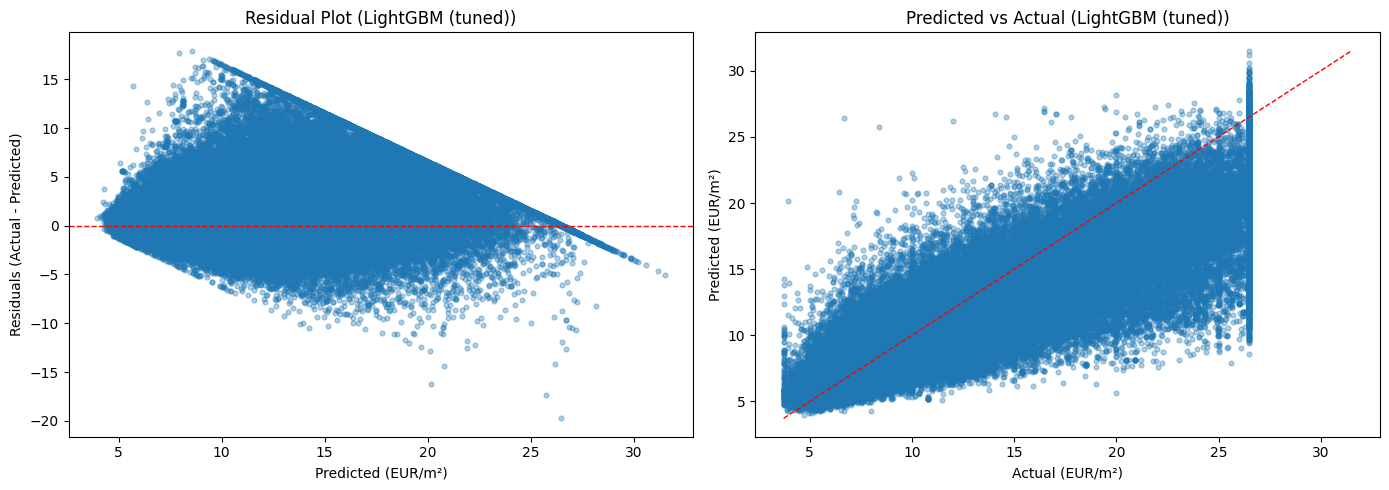

Plots generated for: LightGBM (tuned)


In [ ]:
# # Residual Plot + Predicted vs Actual (Model A, EUR/m²)
# import matplotlib.pyplot as plt

# preds_map = {}
# if 'y_pred_lgbm_tuned' in locals():
#     preds_map['LightGBM (tuned)'] = y_pred_lgbm_tuned
# if 'y_pred_ebm_tuned' in locals():
#     preds_map['EBM (tuned)'] = y_pred_ebm_tuned
# if 'y_pred_igann_tuned' in locals():
#     preds_map['IGANN (tuned)'] = y_pred_igann_tuned
# if 'y_pred_ridge_tuned' in locals():
#     preds_map['Ridge (tuned)'] = y_pred_ridge_tuned
# if 'y_pred_xgb_tuned' in locals():
#     preds_map['XGBoost (tuned)'] = y_pred_xgb_tuned
# if 'y_pred_tabicl' in locals():
#     preds_map['TabICLv2'] = y_pred_tabicl

# if not preds_map:
#     raise RuntimeError('No predictions found. Run model training first.')

# if 'df_results' in locals() and len(df_results) > 0:
#     candidates = [m for m in df_results.index.tolist() if m in preds_map]
#     best_model = candidates[0] if candidates else list(preds_map.keys())[0]
# else:
#     best_model = list(preds_map.keys())[0]

# y_true_plot = np.asarray(y_test)
# y_pred_plot = np.asarray(preds_map[best_model])
# residuals = y_true_plot - y_pred_plot

# fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# axes[0].scatter(y_pred_plot, residuals, alpha=0.35, s=12)
# axes[0].axhline(0, color='red', linestyle='--', linewidth=1)
# axes[0].set_title(f'Residual Plot ({best_model})')
# axes[0].set_xlabel('Predicted (EUR/m²)')
# axes[0].set_ylabel('Residuals (Actual - Predicted)')

# axes[1].scatter(y_true_plot, y_pred_plot, alpha=0.35, s=12)
# min_v = min(y_true_plot.min(), y_pred_plot.min())
# max_v = max(y_true_plot.max(), y_pred_plot.max())
# axes[1].plot([min_v, max_v], [min_v, max_v], 'r--', linewidth=1)
# axes[1].set_title(f'Predicted vs Actual ({best_model})')
# axes[1].set_xlabel('Actual (EUR/m²)')
# axes[1].set_ylabel('Predicted (EUR/m²)')

# plt.tight_layout()
# plt.show()

# print(f'Plots generated for: {best_model}')